In [65]:
import numpy as np
import pandas as pd

Reading and inspecting the dataset

In [66]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

In [67]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [68]:
df.shape

(7043, 21)

##### so the shape is telling that the data has 7043 row and 21 columns which means 7043 customer and 21 feature

##### checking the columns /features

In [69]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


as whitespaces are not considered empty values i checked for them in the df first

In [71]:
for col in df.columns:
    count = (df[col].astype(str).str.strip() == '').sum()

    if count > 0:
        print(f"{col}: {count} whitespaces")

TotalCharges: 11 whitespaces


##### i have noticed that totalcharges column its type is object which not making sense as i expect numbers and any '' '' whitespaces changed to NAN

In [72]:
zero_tenure = df[df['tenure'] == 0]

print(zero_tenure[['tenure', 'TotalCharges']])

      tenure TotalCharges
488        0             
753        0             
936        0             
1082       0             
1340       0             
3331       0             
3826       0             
4380       0             
5218       0             
6670       0             
6754       0             


In [73]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce')

In [74]:
zero_tenure = df[df['tenure'] == 0]

print(zero_tenure[['tenure', 'TotalCharges']])

      tenure  TotalCharges
488        0           NaN
753        0           NaN
936        0           NaN
1082       0           NaN
1340       0           NaN
3331       0           NaN
3826       0           NaN
4380       0           NaN
5218       0           NaN
6670       0           NaN
6754       0           NaN


In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### transforming the totalcharges column to numerical values , making sure to remove whitespaces , change any non converting value to NAN
#####'' '' will be NANs

In [76]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


double checking

In [77]:
df['TotalCharges'].isnull().sum()

np.int64(11)

filling the NAN values with zeros instead because this make sense logically as these customers have no accmulated fees

In [78]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

checking the nulls after filling giving zeros

In [79]:
df['TotalCharges'].isnull().sum()

np.int64(0)

checking duplicates

In [80]:
df.duplicated().sum()

np.int64(0)

Outlier detection and visulatization

In [86]:
numerical_cols = df.select_dtypes(include='number').columns

for col in numerical_cols:
    median = df[col].median()
    mad = np.median(np.abs(df[col] - median))

    if mad == 0:
        continue

    modified_z = 0.6745 * (df[col] - median) / mad

    outliers_count = (modified_z.abs() > 3.5).sum()

    print(col, ":", outliers_count, "outliers")

tenure : 0 outliers
MonthlyCharges : 0 outliers
TotalCharges : 136 outliers


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

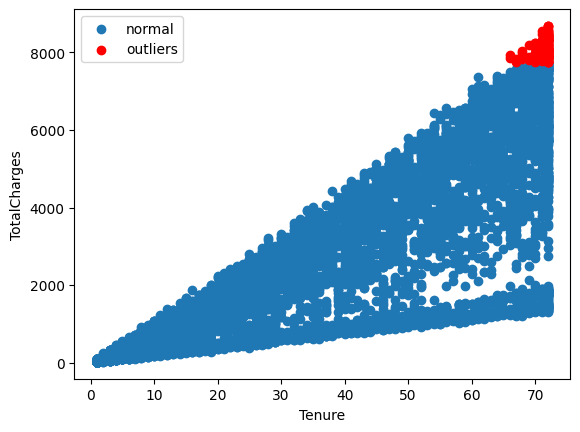

In [51]:
plt.scatter(normal['tenure'], normal['TotalCharges'], label='normal')

plt.scatter(outliers['tenure'], outliers['TotalCharges'], color='red', label='outliers')

plt.xlabel('Tenure')
plt.ylabel('TotalCharges')
plt.legend()
plt.show()

Found 136 outliers but from the business logic it make sense that these are customers that have high tenure may have high totalcharges because of the long time of subscribtions

tenure :(The number of months the customer has been with the company from the day they joined until the time the data was collected)

the red dots (outliers) are all clustered way up at the very top of the TotalCharges, and it clearly shows that they aren't random mistakes; these are the people with the highest Value for the company

If outlier handling is necessary, regardless outliers are valid according to business logic, I would apply log transformation to compress the scale of the data.

 This will help me reduce the difference between small and large values, making extreme values have less impact for ML algorithms that will be used in advance

Text(0, 0.5, 'TotalCharges')

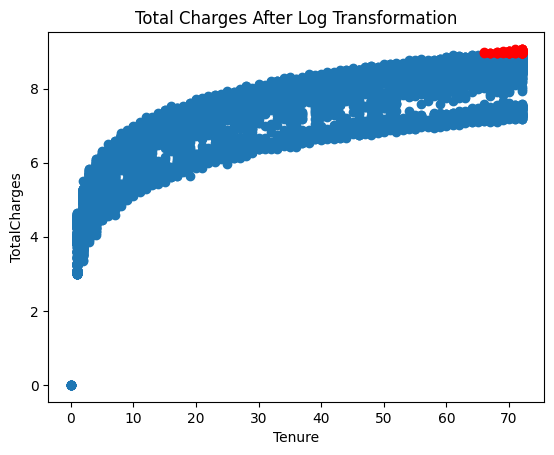

In [62]:
#df['TotalCharges_log'] = np.log1p(df['TotalCharges'])

normal = df[~outliers_mask.fillna(False)]
outliers = df[outliers_mask.fillna(False)]


plt.scatter(normal['tenure'], normal['TotalCharges_log'], label='Normal')

plt.scatter(
    outliers['tenure'],
    outliers['TotalCharges_log'],
    color='red',
    label='Outliers'
)

plt.title('Total Charges After Log Transformation')
plt.xlabel('Tenure')
plt.ylabel('TotalCharges')


**Customer and tenure distribution chart (histogram)**

shows that:

*    31.04% of customers have been with the company for 12 months or less
*    21.06% have maintained their subscriptions for at least 60 months.


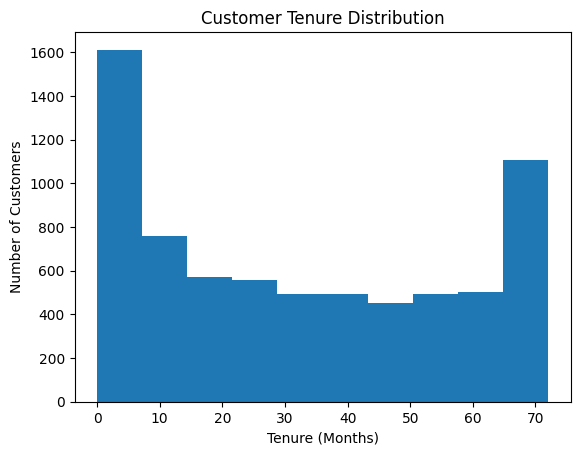

In [ ]:
plt.hist(df['tenure'])

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
print("tenure(months of customer's subscription) <= 12 months:")
t= df['tenure']

print((t <= 12).sum())

print("tenure >= 60 months:")
print((t >= 60).sum())

tenure(months of customer's subscription) <= 12 months:
2186
tenure >= 60 months:
1483


In [ ]:
print("Percentage of customers with tenure <= 12 months:")
print((df['tenure'] <= 12).sum() / len(df) * 100)

print("Percentage of customers with tenure >= 60 months:")
print((df['tenure'] >= 60).sum() / len(df) * 100)

Percentage of customers with tenure <= 12 months:
31.037909981541954
Percentage of customers with tenure >= 60 months:
21.05636802498935


In [ ]:
print("Percentage <= 12 months:")
print((t <= 12).mean() * 100)

print("Percentage >= 60 months:")
print((t >= 60).mean() * 100)


Percentage <= 12 months:
31.037909981541954
Percentage >= 60 months:
21.05636802498935


**customer Churn distribution chart (countplot)**

the observation for the customer column with the target column shows that :
* 73.46% of customers did not churn (did not leave)
* 26.54% leave and broke their subscriptions


This indicates a class imbalance in the target column, which should be considered when building model to be trained on this data  


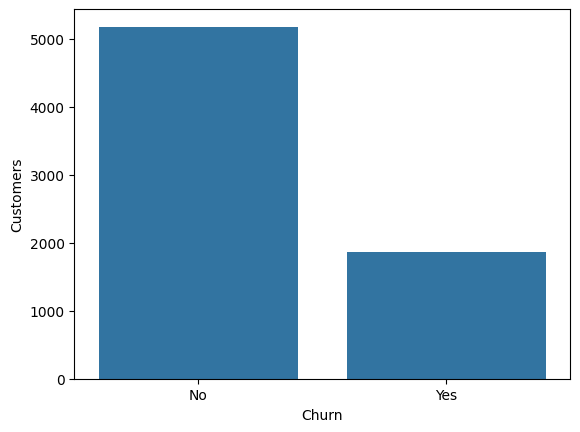

In [ ]:
sns.countplot(x='Churn', data=df)
plt.ylabel('Customers')

plt.show()

In [ ]:
x=df['Churn']
print(x.value_counts())
print(x.value_counts() / len(df) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


# Solve the data imbalance by using augmentation algorithm

**Monthly Charges vs Churn (boxplot)**

Customers who churned had higher monthly charges than those who stayed


*   The average monthly charge was 74.4 for churned customers
*    61.2 for non-churned customers

customers who canceled their subscription have a higher average monthly bill (median around 80)

 This means that higher monthly costs are one of the main drivers of churn

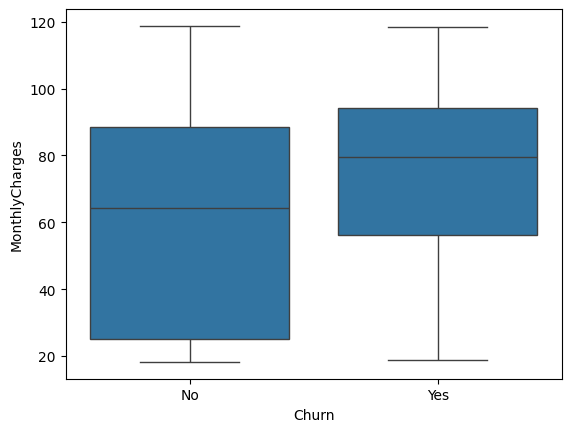

In [ ]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.show()

In [6]:
yes_mean = df[df['Churn'] == 'Yes']['MonthlyCharges'].mean()
no_mean = df[df['Churn'] == 'No']['MonthlyCharges'].mean()

print(f"Yes: {yes_mean}, No: {no_mean}")

Yes: 74.44133226324237, No: 61.26512369540008


**The churn Rate depending on contract Type (line plot)**



*   sharp downward in the churn rate as the contract duration increases

*   Month-to-month contracts record the highest churn rate, which drops for one-year contracts and reaches its lowest point for two-year contracts

*   Inverse relationship between contract length of time and churn


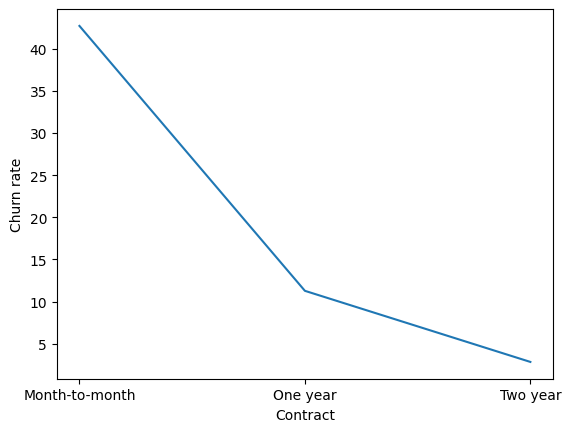

In [ ]:
sns.lineplot(x=churn_rate.index, y=churn_rate.values)

plt.xlabel('Contract')
plt.ylabel('Churn rate')

plt.show()

## SQL

In [5]:
!pip install pandasql

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pandasql: filename=pandasql-0.7.3-py3-none-any.whl size=26869 sha256=a756bcfe5e7b820ef1b3167f59d06f10da36c9b4ab7c6beb75a062b5b662be94
  Stored in directory: /root/.cache/pip/wheels/b4/d0/8c/a6b366870bf041849cd96e03b71641e082f8d6456269b603b7
Successfully built pandasql


In [6]:
from pandasql import sqldf

writting a query to find how many customers are in the subscription of each contract type

The result knowing the count of customer in each type of contract

goal : from each contract type how many customer applied for this

In [50]:
query1 = """
   SELECT Contract, COUNT(*) AS count_of_customers
FROM df
GROUP BY Contract;
"""

query1 = sqldf(query1, {'df': df})
print(result_contract)

         Contract  count_of_customers
0  Month-to-month                3875
1        One year                1473
2        Two year                1695


writting a query to see in which internet services the customers leaves the subscription more

the result shows that customers with fiber optic internet service has the highest number of churned customers

goal : from each internet service type how many customer churns

In [48]:
query2 = """
SELECT InternetService, COUNT(*) AS churned_customers
FROM df
WHERE Churn = 'Yes'
GROUP BY InternetService
"""

query2  = sqldf(query_contract2, {'df': df})
print(query2)

  InternetService  churned_customers
0             DSL                459
1     Fiber optic               1297
2              No                113


creating 2 tables to test the JOIN
I created table for customers and another one for services

In [9]:
df_customers = df[['customerID', 'Contract', 'PaymentMethod']]
df_services = df[['customerID', 'InternetService', 'TechSupport', 'Churn']]
print(df_customers.head())

print(df_services.head())

   customerID        Contract              PaymentMethod
0  7590-VHVEG  Month-to-month           Electronic check
1  5575-GNVDE        One year               Mailed check
2  3668-QPYBK  Month-to-month               Mailed check
3  7795-CFOCW        One year  Bank transfer (automatic)
4  9237-HQITU  Month-to-month           Electronic check
   customerID InternetService TechSupport Churn
0  7590-VHVEG             DSL          No    No
1  5575-GNVDE             DSL          No    No
2  3668-QPYBK             DSL          No   Yes
3  7795-CFOCW             DSL         Yes    No
4  9237-HQITU     Fiber optic          No   Yes


writting a query to apply left join between these 2 tables as i choose from the left (constant) table the customerid and contract column and the join is applied on the right table as i choose from it the internetservice and churn column

the result shows that mainly cutomers with contract one year and internet service DSL has churn result equals to NO

goal to see combination between the contract and internet service that a certain customers have and are these who churn

In [10]:
query_left = """
    SELECT
        c.customerID,
        c.Contract,
        s.InternetService,
        s.Churn
    FROM df_customers c
    LEFT JOIN df_services s
        ON c.customerID = s.customerID;
"""

result_left = sqldf(query_left, {'df_customers': df_customers, 'df_services': df_services})
display(result_left.head(10))

,customerID,Contract,InternetService,Churn
0,7590-VHVEG,Month-to-month,DSL,No
1,5575-GNVDE,One year,DSL,No
2,3668-QPYBK,Month-to-month,DSL,Yes
3,7795-CFOCW,One year,DSL,No
4,9237-HQITU,Month-to-month,Fiber optic,Yes
5,9305-CDSKC,Month-to-month,Fiber optic,Yes
6,1452-KIOVK,Month-to-month,Fiber optic,No
7,6713-OKOMC,Month-to-month,DSL,No
8,7892-POOKP,Month-to-month,Fiber optic,Yes
9,6388-TABGU,One year,DSL,No
